Harrison Eilers — DATA 3402

https://www.kaggle.com/competitions/playground-series-s4e8

The goal of this project is to predict whether a mushroom is edible or poisonous from its characteristics. Each row represents one mushroom example. The training data has 3,116,945 rows and 20 input features, plus an ID and the target column, class. The target uses e for edible and p for poisonous.

This notebook explores the features, missing values, class balance, and relationships in the data before modeling.

In [13]:
# Step 1: Load the mushroom data
import pandas as pd

df = pd.read_csv("/content/train.csv", low_memory=False)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Rows: 3116945
Columns: 22


,id,class,cap-diameter,cap-shape,cap-surface,cap-color,does-bruise-or-bleed,gill-attachment,gill-spacing,gill-color,...,stem-root,stem-surface,stem-color,veil-type,veil-color,has-ring,ring-type,spore-print-color,habitat,season
0,0,e,8.80,f,s,u,f,a,c,w,...,NaN,NaN,w,NaN,NaN,f,f,NaN,d,a
1,1,p,4.51,x,h,o,f,a,c,n,...,NaN,y,o,NaN,NaN,t,z,NaN,d,w
2,2,e,6.94,f,s,b,f,x,c,w,...,NaN,s,n,NaN,NaN,f,f,NaN,l,w
3,3,e,3.88,f,y,g,f,s,NaN,g,...,NaN,NaN,w,NaN,NaN,f,f,NaN,d,u
4,4,e,5.85,x,l,w,f,d,NaN,w,...,NaN,NaN,w,NaN,NaN,f,f,NaN,g,a


In [14]:
# Step 2: Inspect the data
df.info()

print("\nMissing values:")
print(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget class counts:")
print(df["class"].value_counts())

print("\nTarget class percentages:")
print((df["class"].value_counts(normalize=True) * 100).round(2))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3116945 entries, 0 to 3116944
Data columns (total 22 columns):
 #   Column                Dtype  
---  ------                -----  
 0   id                    int64  
 1   class                 object 
 2   cap-diameter          float64
 3   cap-shape             object 
 4   cap-surface           object 
 5   cap-color             object 
 6   does-bruise-or-bleed  object 
 7   gill-attachment       object 
 8   gill-spacing          object 
 9   gill-color            object 
 10  stem-height           float64
 11  stem-width            float64
 12  stem-root             object 
 13  stem-surface          object 
 14  stem-color            object 
 15  veil-type             object 
 16  veil-color            object 
 17  has-ring              object 
 18  ring-type             object 
 19  spore-print-color     object 
 20  habitat               object 
 21  season                object 
dtypes: float64(3), int64(1), object(18)
memory

In [16]:
# Check the dataset size and final rows
print("Rows and columns:", df.shape)
display(df.tail(3))

Rows and columns: (3116945, 22)


,id,class,cap-diameter,cap-shape,cap-surface,cap-color,does-bruise-or-bleed,gill-attachment,gill-spacing,gill-color,...,stem-root,stem-surface,stem-color,veil-type,veil-color,has-ring,ring-type,spore-print-color,habitat,season
3116942,3116942,p,7.82,x,e,e,f,a,NaN,w,...,NaN,NaN,y,NaN,w,t,z,NaN,d,a
3116943,3116943,e,9.45,p,i,n,t,e,NaN,p,...,NaN,y,w,NaN,NaN,t,p,NaN,d,u
3116944,3116944,p,3.20,x,s,g,f,d,c,w,...,NaN,NaN,w,NaN,NaN,f,f,NaN,g,u


In [17]:
# Step 3: Create a feature summary table
summary = []

for column in df.columns:
    values = df[column]

    if column == "id":
        role = "ID"
        value_range = "Unique row identifier"
    elif column == "class":
        role = "Target"
        value_range = "e = edible, p = poisonous"
    elif pd.api.types.is_numeric_dtype(values):
        role = "Numerical"
        value_range = f"{values.min()} to {values.max()}"
    else:
        role = "Categorical"
        value_range = ", ".join(
            values.value_counts().head(10).index.astype(str)
        )

    summary.append({
        "Feature": column,
        "Role": role,
        "Range or top 10 categories": value_range,
        "Unique values": values.nunique(),
        "Missing": values.isna().sum(),
        "Missing %": round(values.isna().mean() * 100, 2)
    })

feature_table = pd.DataFrame(summary)
display(feature_table)

,Feature,Role,Range or top 10 categories,Unique values,Missing,Missing %
0,id,ID,Unique row identifier,3116945,0,0.00
1,class,Target,"e = edible, p = poisonous",2,0,0.00
2,cap-diameter,Numerical,0.03 to 80.67,3913,4,0.00
3,cap-shape,Categorical,"x, f, s, b, o, p, c, d, e, n",74,40,0.00
4,cap-surface,Categorical,"t, s, y, h, g, d, k, e, i, w",83,671023,21.53
5,cap-color,Categorical,"n, y, w, g, e, o, p, r, u, b",78,12,0.00
6,does-bruise-or-bleed,Categorical,"f, t, w, c, h, b, y, a, x, s",26,8,0.00
7,gill-attachment,Categorical,"a, d, x, e, s, p, f, c, u, w",78,523936,16.81
8,gill-spacing,Categorical,"c, d, f, e, a, s, b, x, t, p",48,1258435,40.37
9,gill-color,Categorical,"w, n, y, p, g, o, k, f, r, e",63,57,0.00


In [18]:
# Step 4: Add feature meanings
meanings = {
    "id": "Row identifier",
    "class": "Edible or poisonous",
    "cap-diameter": "Width of the mushroom cap",
    "cap-shape": "Shape of the cap",
    "cap-surface": "Surface texture of the cap",
    "cap-color": "Color of the cap",
    "does-bruise-or-bleed": "Whether bruising or bleeding occurs",
    "gill-attachment": "How the gills attach to the stem",
    "gill-spacing": "Spacing between the gills",
    "gill-color": "Color of the gills",
    "stem-height": "Height of the stem",
    "stem-width": "Width of the stem",
    "stem-root": "Type of stem base or root",
    "stem-surface": "Surface texture of the stem",
    "stem-color": "Color of the stem",
    "veil-type": "Type of protective mushroom covering",
    "veil-color": "Color of the veil",
    "has-ring": "Whether a ring is present on the stem",
    "ring-type": "Type of ring on the stem",
    "spore-print-color": "Color of the deposited spores",
    "habitat": "Environment where the mushroom grows",
    "season": "Season when the mushroom occurs"
}

feature_table["Meaning"] = feature_table["Feature"].map(meanings)
display(feature_table)

,Feature,Role,Range or top 10 categories,Unique values,Missing,Missing %,Meaning
0,id,ID,Unique row identifier,3116945,0,0.00,Row identifier
1,class,Target,"e = edible, p = poisonous",2,0,0.00,Edible or poisonous
2,cap-diameter,Numerical,0.03 to 80.67,3913,4,0.00,Width of the mushroom cap
3,cap-shape,Categorical,"x, f, s, b, o, p, c, d, e, n",74,40,0.00,Shape of the cap
4,cap-surface,Categorical,"t, s, y, h, g, d, k, e, i, w",83,671023,21.53,Surface texture of the cap
5,cap-color,Categorical,"n, y, w, g, e, o, p, r, u, b",78,12,0.00,Color of the cap
6,does-bruise-or-bleed,Categorical,"f, t, w, c, h, b, y, a, x, s",26,8,0.00,Whether bruising or bleeding occurs
7,gill-attachment,Categorical,"a, d, x, e, s, p, f, c, u, w",78,523936,16.81,How the gills attach to the stem
8,gill-spacing,Categorical,"c, d, f, e, a, s, b, x, t, p",48,1258435,40.37,Spacing between the gills
9,gill-color,Categorical,"w, n, y, p, g, o, k, f, r, e",63,57,0.00,Color of the gills


In [19]:
# Step 5: Add notes about potential data issues
feature_table["Notes"] = ""

feature_table.loc[
    feature_table["Missing %"] > 50, "Notes"
] = "More than half missing; decide how to handle before modeling."

feature_table.loc[
    feature_table["Feature"].isin(
        ["does-bruise-or-bleed", "has-ring"]
    ), "Notes"
] = "Unexpected categories beyond t/f; investigate."

feature_table.loc[
    feature_table["Feature"] == "id", "Notes"
] = "Exclude from model inputs."

feature_table.loc[
    feature_table["Role"] == "Numerical", "Notes"
] = "Inspect zero and extreme values; do not remove automatically."

display(feature_table)

,Feature,Role,Range or top 10 categories,Unique values,Missing,Missing %,Meaning,Notes
0,id,ID,Unique row identifier,3116945,0,0.00,Row identifier,Exclude from model inputs.
1,class,Target,"e = edible, p = poisonous",2,0,0.00,Edible or poisonous,
2,cap-diameter,Numerical,0.03 to 80.67,3913,4,0.00,Width of the mushroom cap,Inspect zero and extreme values; do not remove...
3,cap-shape,Categorical,"x, f, s, b, o, p, c, d, e, n",74,40,0.00,Shape of the cap,
4,cap-surface,Categorical,"t, s, y, h, g, d, k, e, i, w",83,671023,21.53,Surface texture of the cap,
5,cap-color,Categorical,"n, y, w, g, e, o, p, r, u, b",78,12,0.00,Color of the cap,
6,does-bruise-or-bleed,Categorical,"f, t, w, c, h, b, y, a, x, s",26,8,0.00,Whether bruising or bleeding occurs,Unexpected categories beyond t/f; investigate.
7,gill-attachment,Categorical,"a, d, x, e, s, p, f, c, u, w",78,523936,16.81,How the gills attach to the stem,
8,gill-spacing,Categorical,"c, d, f, e, a, s, b, x, t, p",48,1258435,40.37,Spacing between the gills,
9,gill-color,Categorical,"w, n, y, p, g, o, k, f, r, e",63,57,0.00,Color of the gills,


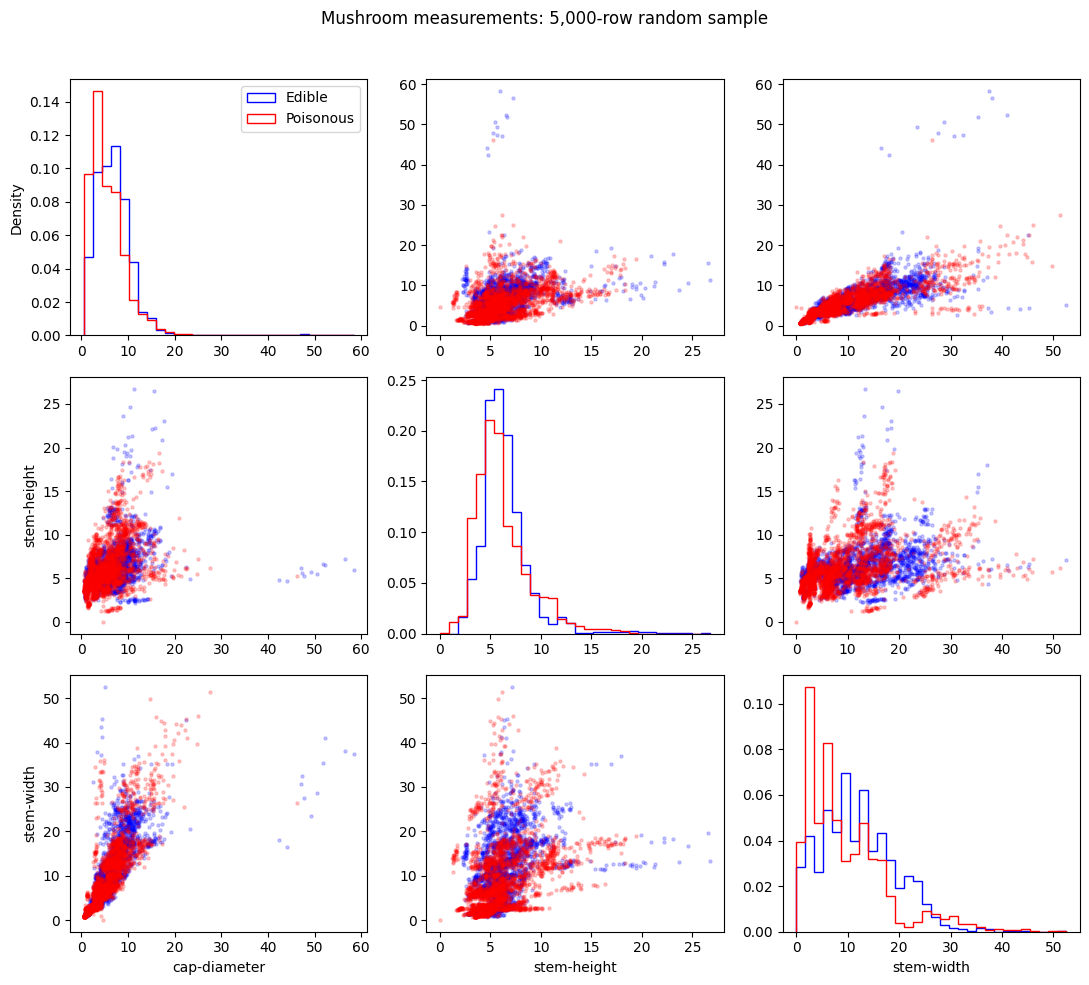

In [20]:
# Step 6: Pair plot of numerical features
import numpy as np
import matplotlib.pyplot as plt

features = ["cap-diameter", "stem-height", "stem-width"]

# A small random sample keeps the plot readable and fast
plot_data = df[features + ["class"]].sample(
    n=5000, random_state=42
)

fig, axes = plt.subplots(3, 3, figsize=(11, 10))

for i, y in enumerate(features):
    for j, x in enumerate(features):
        ax = axes[i, j]
        bins = np.histogram_bin_edges(
            plot_data[x].dropna(), bins=30
        )

        for label, color, name in [
            ("e", "blue", "Edible"),
            ("p", "red", "Poisonous")
        ]:
            group = plot_data[plot_data["class"] == label]

            if i == j:
                ax.hist(
                    group[x].dropna(),
                    bins=bins,
                    density=True,
                    histtype="step",
                    color=color,
                    label=name
                )
            else:
                ax.scatter(
                    group[x], group[y],
                    s=5, alpha=0.2,
                    color=color, label=name
                )

        if i == 2:
            ax.set_xlabel(x)
        if j == 0:
            ax.set_ylabel("Density" if i == j else y)

axes[0, 0].legend()
fig.suptitle("Mushroom measurements: 5,000-row random sample")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [21]:
# Step 7: Counts and percentages for categorical features
categorical_features = [
    column for column in df.select_dtypes(include="object").columns
    if column != "class"
]

for column in categorical_features:
    counts = df[column].fillna("Missing").value_counts()

    table = pd.DataFrame({
        "Count": counts,
        "Percent": (counts / len(df) * 100).round(2)
    })

    print(f"\n{column}")
    display(table)


cap-shape


,Count,Percent
cap-shape,,
x,1436026,46.07
f,676238,21.70
s,365146,11.71
b,318646,10.22
o,108835,3.49
...,...,...
17.44,1,0.00
4.33,1,0.00
2.82,1,0.00



cap-surface


,Count,Percent
cap-surface,,
Missing,671023,21.53
t,460777,14.78
s,384970,12.35
y,327826,10.52
h,284460,9.13
...,...,...
10.34,1,0.00
10.1,1,0.00
1.08,1,0.00



cap-color


,Count,Percent
cap-color,,
n,1359542,43.62
y,386627,12.40
w,379442,12.17
g,210825,6.76
e,197290,6.33
...,...,...
20.02,1,0.00
20,1,0.00
25.98,1,0.00


... (24 outputs left out)


habitat


,Count,Percent
habitat,,
d,2177573,69.86
g,454908,14.59
l,171892,5.51
m,150969,4.84
h,120137,3.85
w,18530,0.59
p,17180,0.55
u,5264,0.17
e,55,0.00



season


,Count,Percent
season,,
a,1543321,49.51
u,1153588,37.01
w,278189,8.93
s,141847,4.55


In [22]:
# Step 8: Compare categories with the target
for column in ["cap-shape", "gill-color", "habitat", "has-ring"]:
    values = df[column].fillna("Missing")

    counts = pd.crosstab(values, df["class"])
    percentages = pd.crosstab(
        values, df["class"], normalize="index"
    ) * 100

    table = counts.rename(columns={
        "e": "Edible count",
        "p": "Poisonous count"
    })

    table["Edible %"] = percentages["e"].round(2)
    table["Poisonous %"] = percentages["p"].round(2)
    table["Total"] = counts.sum(axis=1)

    print(f"\n{column}")
    display(table.sort_values("Total", ascending=False).head(10))


cap-shape


class,Edible count,Poisonous count,Edible %,Poisonous %,Total
cap-shape,,,,,
x,703414,732612,48.98,51.02,1436026
f,330042,346196,48.81,51.19,676238
s,164514,200632,45.05,54.95,365146
b,72321,246325,22.70,77.30,318646
o,35392,73443,32.52,67.48,108835
p,57826,49141,54.06,45.94,106967
c,47789,56731,45.72,54.28,104520
d,26,39,40.00,60.00,65
e,39,21,65.00,35.00,60



gill-color


class,Edible count,Poisonous count,Edible %,Poisonous %,Total
gill-color,,,,,
w,532430,399108,57.16,42.84,931538
n,154931,388455,28.51,71.49,543386
y,197624,271840,42.10,57.90,469464
p,140815,202811,40.98,59.02,343626
g,110114,102050,51.90,48.10,212164
o,75829,81290,48.26,51.74,157119
k,54083,73887,42.26,57.74,127970
f,58665,61029,49.01,50.99,119694
r,17966,44833,28.61,71.39,62799



habitat


class,Edible count,Poisonous count,Edible %,Poisonous %,Total
habitat,,,,,
d,1025988,1151585,47.12,52.88,2177573
g,148026,306882,32.54,67.46,454908
l,104008,67884,60.51,39.49,171892
m,69806,81163,46.24,53.76,150969
h,39748,80389,33.09,66.91,120137
w,18449,81,99.56,0.44,18530
p,65,17115,0.38,99.62,17180
u,5221,43,99.18,0.82,5264
e,43,12,78.18,21.82,55



has-ring


class,Edible count,Poisonous count,Edible %,Poisonous %,Total
has-ring,,,,,
f,1105637,1263183,46.67,53.33,2368820
t,305847,442135,40.89,59.11,747982
Missing,12,12,50.00,50.00,24
r,9,7,56.25,43.75,16
h,3,10,23.08,76.92,13
l,9,2,81.82,18.18,11
c,2,9,18.18,81.82,11
s,5,6,45.45,54.55,11
p,6,5,54.55,45.45,11


observations:

1. Cap shape is related to mushroom class. Category b was 77.30% poisonous, compared with 51.02% for category x.

2. Habitat showed large differences between classes. Category p was 99.62% poisonous, while category w was 99.56% edible in this dataset.

3. Having a ring did not clearly separate the classes. Mushrooms with rings were 59.11% poisonous, compared with 53.33% for those without rings.


Several columns have many missing values, including veil-type at 94.88% missing. The has-ring column also contains rare, unexpected values beyond t and f. I need to investigate these categories and decide how to handle missing values before training a model.